# Задание 8. Сравнение алгоритмов классификации SMS

**Проект:** SMS Guard · **Автор:** Омаров М.Е., SIS-2304

Код сравнения — `ml/train_sms.py` (тот же цикл без ноутбука: `python -m ml.train_sms`).

**Данные.** Итоговая модель должна работать на английском, русском и казахском, поэтому все алгоритмы
обучаются на одинаковой выборке: UCI train (английский, разбиение задания 6) + синтетический ru/kk train
(разбиение по шаблонам). Validation и test составлены так же. Ручной набор `custom_ru_kk.csv` (150 SMS)
используется только для проверки.

**Правила против утечки:** векторизатор внутри Pipeline; подбор гиперпараметров — кросс-валидацией на train;
порог и выбор модели — на validation; test — один раз для выбранной модели.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (ConfusionMatrixDisplay, auc, average_precision_score, precision_recall_curve,
                             roc_curve)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)

from ml import train_sms as ts  # noqa: E402
from ml.metrics import compute_metrics  # noqa: E402

FIG_DIR = PROJECT_ROOT / "docs" / "figures"
data = ts.load_data()
sizes = pd.DataFrame({name: part.groupby("lang")["label"].agg(["size", "sum"]).stack()
                      for name, part in [("train", data.train), ("val", data.val), ("test", data.test)]})
sizes.index = [f"{lang} — {'всего' if k == 'size' else 'мошеннических'}" for lang, k in sizes.index]
sizes

,train,val,test
en — всего,3594,770,771
en — мошеннических,433,93,93
kk — всего,630,182,188
kk — мошеннических,305,97,98
ru — всего,628,185,187
ru — мошеннических,305,97,98


## 1. Подбор гиперпараметров: 4 алгоритма × GridSearchCV

| Алгоритм | Сетка |
| :--- | :--- |
| Multinomial Naive Bayes | `alpha` ∈ {0,01; 0,05; 0,1; 0,5; 1} |
| Logistic Regression (`class_weight='balanced'`) | `C` ∈ {0,1; 1; 10; 100} |
| Linear SVM + `CalibratedClassifierCV` (вероятности) | `C` ∈ {0,01; 0,1; 1; 10} |
| Random Forest (`class_weight='balanced_subsample'`) | `n_estimators` ∈ {200; 400}, `max_depth` ∈ {None; 60} |

Кросс-валидация: 5 фолдов, метрика **F2** для класса «мошенничество». Вместо обычного `StratifiedKFold`
используется `StratifiedGroupKFold` с той же стратификацией: группа — шаблон синтетического сообщения
(у английских SMS каждое сообщение — своя группа). Иначе похожие сообщения одного шаблона попадают и в обучающий,
и в проверочный фолд, и оценка CV завышается.

Признаки — лучший вариант задания 6: TF-IDF слов + символьные n-граммы + 8 ручных признаков.

In [2]:
start = time.perf_counter()
algo_results, variant_results, models = ts.run_comparison(data, verbose=False)
print(f"Сравнение заняло {time.perf_counter() - start:.0f} с")

Сравнение заняло 276 с


## 2. Сводная таблица на validation

**Порог.** Для каждой модели на validation подобран минимальный порог, при котором Precision ≥ 0,90
(а Recall при этом максимален). В задании 8 указано Precision ≥ 0,85, но такое правило выжимает Precision
ровно до 0,85 — меньше требования раздела 3.4 к SMS-модели (Precision ≥ 0,90). Поэтому цель поднята до 0,90;
условие задания (≥ 0,85) при этом тоже выполняется.

In [3]:
def row(r, metrics_key="val_at_threshold"):
    m = r[metrics_key]
    return {"Алгоритм": r["title"], "Параметры": r["best_params"], "CV F2": r["cv_f2"],
            "Порог": r["threshold"], "Accuracy": m["accuracy"], "Precision": m["precision"],
            "Recall": m["recall"], "F1": m["f1"], "F2": m["f2"], "ROC-AUC": m["roc_auc"],
            "PR-AUC": m["pr_auc"], "Обучение, с": r["fit_seconds"], "Предсказание, мс": r["predict_ms"]}


table = pd.DataFrame([row(r) for r in algo_results]).set_index("Алгоритм")
print("Validation, порог подобран (Precision ≥ 0,90):")
table

Validation, порог подобран (Precision ≥ 0,90):


,Параметры,CV F2,Порог,Accuracy,Precision,Recall,F1,F2,ROC-AUC,PR-AUC,"Обучение, с","Предсказание, мс"
Алгоритм,,,,,,,,,,,,
Multinomial Naive Bayes,{'alpha': 0.05},0.9164,0.9999,0.9507,0.9024,0.9024,0.9024,0.9024,0.9847,0.9718,21.6,4.97
Logistic Regression,{'C': 100},0.9553,0.0478,0.9692,0.9013,0.9861,0.9418,0.9679,0.9972,0.9950,18.8,4.50
Linear SVM (калибровка),{'estimator__C': 10},0.9401,0.2474,0.9683,0.9010,0.9826,0.9400,0.9651,0.9971,0.9945,21.0,5.98
Random Forest,"{'max_depth': None, 'n_estimators': 400}",0.9334,0.3050,0.9692,0.9038,0.9826,0.9416,0.9658,0.9963,0.9934,68.4,80.16


In [4]:
print("Для сравнения — те же модели при пороге 0,5:")
pd.DataFrame([{**row(r, "val_at_0_5"), "Порог": 0.5} for r in algo_results]).set_index("Алгоритм")[
    ["Precision", "Recall", "F1", "F2"]]

Для сравнения — те же модели при пороге 0,5:


,Precision,Recall,F1,F2
Алгоритм,,,,
Multinomial Naive Bayes,0.7971,0.9443,0.8644,0.9106
Logistic Regression,1.0000,0.9721,0.9859,0.9776
Linear SVM (калибровка),1.0000,0.9791,0.9894,0.9832
Random Forest,0.9928,0.9582,0.9752,0.9649


In [5]:
by_lang = pd.DataFrame([{"Алгоритм": r["title"], "Язык": lang, **{k: m[k] for k in ("precision", "recall", "f1")},
                         "FP": m["confusion_matrix"]["fp"], "FN": m["confusion_matrix"]["fn"]}
                        for r in algo_results for lang, m in r["val_by_lang"].items()])
print("Validation по языкам (порог 0,5):")
by_lang.pivot(index="Алгоритм", columns="Язык", values=["recall", "precision"]).round(3)

Validation по языкам (порог 0,5):


recall            precision              
Язык                        en   kk    ru        en     kk     ru
Алгоритм                                                         
Linear SVM (калибровка)  0.936  1.0  1.00     1.000  1.000  1.000
Logistic Regression      0.914  1.0  1.00     1.000  1.000  1.000
Multinomial Naive Bayes  0.828  1.0  1.00     0.987  0.752  0.729
Random Forest            0.882  1.0  0.99     0.976  1.000  1.000

## 3. ROC- и PR-кривые всех моделей (validation)

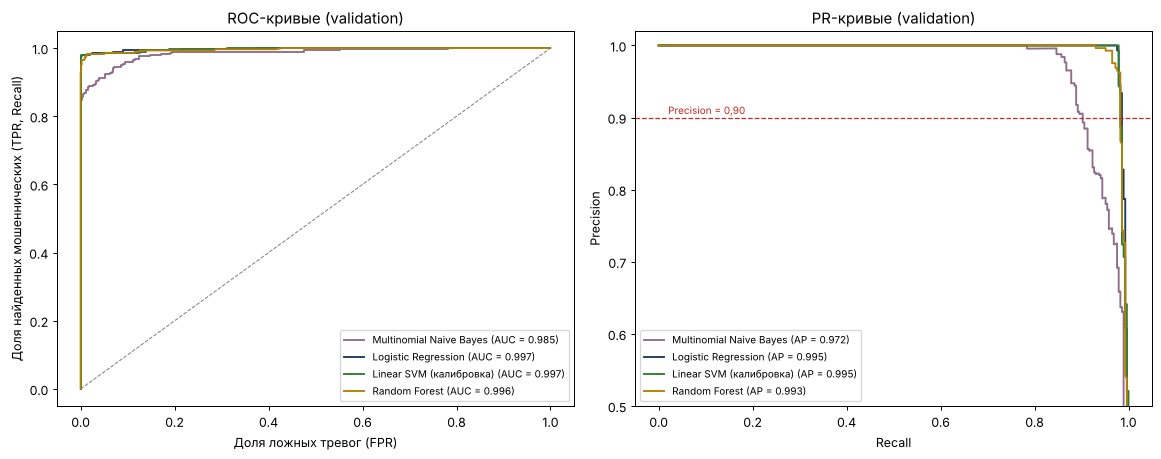

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
colors = {"naive_bayes": "#8e6c8a", "logreg": "#1f3a5f", "linear_svm": "#2e7d32", "random_forest": "#b58105"}
y_val = data.val["label"].to_numpy()
probas = {name: model.predict_proba(data.val[ts.X_COLS])[:, 1] for name, model in models.items()}
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_val, proba)
    axes[0].plot(fpr, tpr, color=colors[name], label=f"{ts.ALGO_TITLES[name]} (AUC = {auc(fpr, tpr):.3f})")
    prec, rec, _ = precision_recall_curve(y_val, proba)
    axes[1].plot(rec, prec, color=colors[name],
                 label=f"{ts.ALGO_TITLES[name]} (AP = {average_precision_score(y_val, proba):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey", linewidth=0.8)
axes[0].set_title("ROC-кривые (validation)")
axes[0].set_xlabel("Доля ложных тревог (FPR)")
axes[0].set_ylabel("Доля найденных мошеннических (TPR, Recall)")
axes[1].axhline(0.90, color="#c62828", linestyle="--", linewidth=1)
axes[1].text(0.02, 0.905, "Precision = 0,90", color="#c62828", fontsize=8)
axes[1].set_title("PR-кривые (validation)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_ylim(0.5, 1.02)
for ax in axes:
    ax.legend(fontsize=8, loc="lower right" if ax is axes[0] else "lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "08_roc_pr_sms.png", dpi=150)

## 4. Сравнение вариантов признаков

Для Naive Bayes и Logistic Regression сетка подбирается заново для каждого варианта признаков.

In [7]:
variants = pd.DataFrame([{"Алгоритм": r["title"], "Признаки": r["variant_title"], "Признаков": r["n_features"],
                          "CV F2": r["cv_f2"], "Precision": r["val_at_threshold"]["precision"],
                          "Recall": r["val_at_threshold"]["recall"], "F2": r["val_at_threshold"]["f2"],
                          "PR-AUC": r["val_at_threshold"]["pr_auc"]} for r in variant_results])
variants.set_index(["Алгоритм", "Признаки"])

Признаков   CV F2  Precision  Recall      F2  PR-AUC
Алгоритм                Признаки                                                                                     
Multinomial Naive Bayes Слова (1–2-граммы)                           10970  0.9249     0.9014  0.8920  0.8939  0.9726
                        Слова без стоп-слов                           7033  0.9179     0.9003  0.9443  0.9351  0.9793
                        Слова + символьные n-граммы                  43939  0.9103     0.9018  0.8641  0.8714  0.9662
                        Слова + символы + 8 ручных признаков         43947  0.9164     0.9024  0.9024  0.9024  0.9718
                        Слова + символы + ручные, без стоп-слов      40010  0.9199     0.9000  0.9094  0.9075  0.9720
Logistic Regression     Слова (1–2-граммы)                           10970  0.9548     0.9010  0.9826  0.9651  0.9887
                        Слова без стоп-слов                           7033  0.9502     0.9010  0.9826  0.9651  0.9439
                        Слова + символьные n-граммы                  43939  0.9620     0.9010  0.9826  0.9651  0.9945
                        Слова + символы + 8 ручных признаков         43947  0.9553     0.9013  0.9861  0.9679  0.9950
                        Слова + символы + ручные, без стоп-слов      40010  0.9508     0.9013  0.9861  0.9679  0.9951

## 5. Выбор итоговой модели

Правило: максимум F2 на validation среди моделей с Precision ≥ 0,85. Модели, отстающие от лучшей меньше чем
на 0,005 по F2, считаются равными; из них выбирается более быстрая и интерпретируемая
(порядок предпочтения: Logistic Regression → Linear SVM → Naive Bayes → Random Forest).

In [8]:
best = ts.choose_best(algo_results)
best_model = models[best["name"]]
print(f"Итоговая модель: {best['title']}, параметры {best['best_params']}, порог {best['threshold']}")
print(f"F2 на validation: {best['val_at_threshold']['f2']}, предсказание {best['predict_ms']} мс на SMS")
table[["F2", "PR-AUC", "Предсказание, мс"]].sort_values("F2", ascending=False)

Итоговая модель: Logistic Regression, параметры {'C': 100}, порог 0.0478
F2 на validation: 0.9679, предсказание 4.5 мс на SMS


,F2,PR-AUC,"Предсказание, мс"
Алгоритм,,,
Logistic Regression,0.9679,0.9950,4.50
Random Forest,0.9658,0.9934,80.16
Linear SVM (калибровка),0.9651,0.9945,5.98
Multinomial Naive Bayes,0.9024,0.9718,4.97


## 6. Подбор порога (выбранная модель)

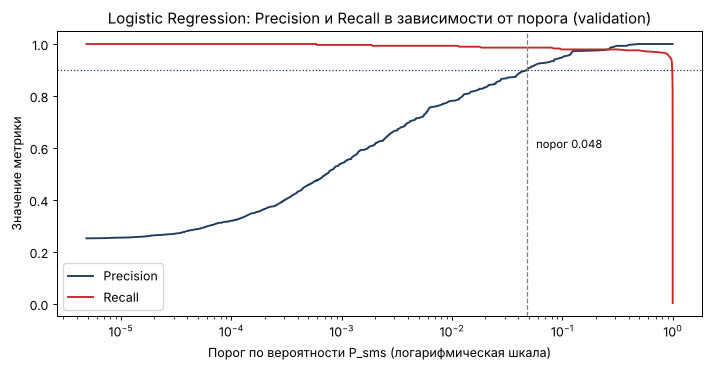

In [9]:
proba_best = probas[best["name"]]
precision, recall, thresholds = precision_recall_curve(y_val, proba_best)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(thresholds, precision[:-1], label="Precision", color="#1f3a5f")
ax.plot(thresholds, recall[:-1], label="Recall", color="#c62828")
ax.axvline(best["threshold"], color="grey", linestyle="--", linewidth=1)
ax.text(best["threshold"] + 0.01, 0.6, f"порог {best['threshold']:.3f}", fontsize=9)
ax.axhline(0.90, color="#1f3a5f", linestyle=":", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("Порог по вероятности P_sms (логарифмическая шкала)")
ax.set_ylabel("Значение метрики")
ax.set_title(f"{best['title']}: Precision и Recall в зависимости от порога (validation)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "08_threshold_sms.png", dpi=150)

## 7. Однократная оценка на test

Модель, выбранная на validation (обучена на train), с порогом из validation. Ниже метрики на всём test,
отдельно по языкам и на ручном ru/kk-наборе.

In [10]:
test_metrics = ts.evaluate_on_test(best_model, best["threshold"], data)
names = {"test_all": "Test — все языки", "test_en": "Test — en (UCI)", "test_ru": "Test — ru (синтетика)",
         "test_kk": "Test — kk (синтетика)", "custom_ru": "Ручной набор — ru", "custom_kk": "Ручной набор — kk"}
test_table = pd.DataFrame([{"Набор": names[k], "SMS": m["n"], "Accuracy": m["accuracy"], "Precision": m["precision"],
                            "Recall": m["recall"], "F1": m["f1"], "F2": m["f2"], "ROC-AUC": m["roc_auc"],
                            "PR-AUC": m["pr_auc"], **m["confusion_matrix"]}
                           for k, m in test_metrics.items()]).set_index("Набор")
test_table

,SMS,Accuracy,Precision,Recall,F1,F2,ROC-AUC,PR-AUC,tn,fp,fn,tp
Набор,,,,,,,,,,,,
Test — все языки,1146,0.9433,0.8237,0.9862,0.8976,0.9487,0.9934,0.9853,796,61,4,285
Test — en (UCI),771,0.9857,0.9271,0.9570,0.9418,0.9509,0.9928,0.9794,671,7,4,89
Test — ru (синтетика),187,0.8075,0.7313,1.0000,0.8448,0.9316,0.9836,0.9865,53,36,0,98
Test — kk (синтетика),188,0.9043,0.8448,1.0000,0.9159,0.9646,0.9885,0.9902,72,18,0,98
Ручной набор — ru,100,0.9900,0.9804,1.0000,0.9901,0.9960,0.9988,0.9988,49,1,0,50
Ручной набор — kk,50,0.9600,0.9259,1.0000,0.9615,0.9843,1.0000,1.0000,23,2,0,25


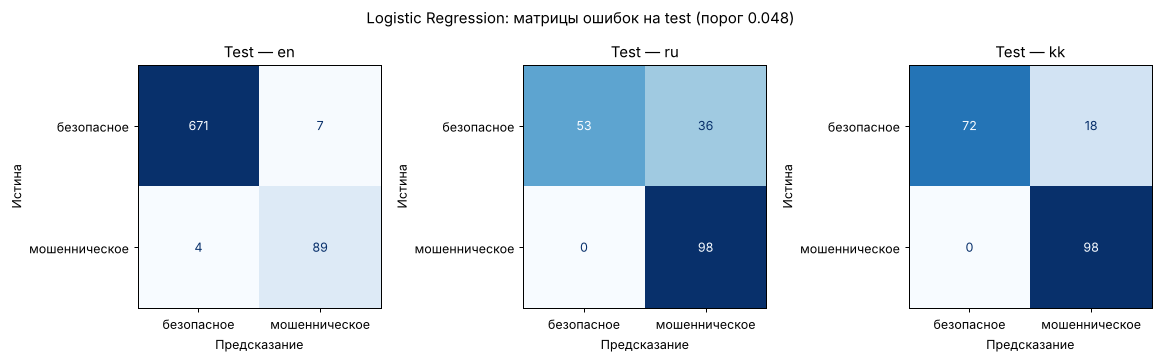

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
proba_test = best_model.predict_proba(data.test[ts.X_COLS])[:, 1]
for ax, lang in zip(axes, ("en", "ru", "kk")):
    mask = (data.test["lang"] == lang).to_numpy()
    ConfusionMatrixDisplay.from_predictions(data.test.loc[mask, "label"], (proba_test[mask] >= best["threshold"]).astype(int),
                                            display_labels=["безопасное", "мошенническое"], cmap="Blues",
                                            colorbar=False, ax=ax, values_format="d")
    ax.set_title(f"Test — {lang}")
    ax.set_xlabel("Предсказание")
    ax.set_ylabel("Истина")
    ax.grid(False)
fig.suptitle(f"{best['title']}: матрицы ошибок на test (порог {best['threshold']:.3f})")
fig.tight_layout()
fig.savefig(FIG_DIR / "08_confusion_test_sms.png", dpi=150)

## 8. Ошибки на test

In [12]:
synth = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "synthetic_ru_kk.csv").set_index("text")
err = data.test.assign(proba=proba_test.round(3), pred=(proba_test >= best["threshold"]).astype(int))
err["category"] = err["text_raw"].map(synth["category"]).fillna("UCI")
fp = err[(err["label"] == 0) & (err["pred"] == 1)]
fn = err[(err["label"] == 1) & (err["pred"] == 0)]
print(f"FP: {len(fp)}, FN: {len(fn)}")
print("\nЛожные тревоги по языкам и категориям:")
fp.groupby(["lang", "category"]).size().rename("FP").to_frame()

FP: 61, FN: 4

Ложные тревоги по языкам и категориям:


FP
lang category          
en   UCI              7
kk   bank_legit       4
     delivery_legit  13
     service          1
ru   bank_legit       9
     delivery_legit  13
     promo_legit     13
     service          1

In [13]:
print("Примеры FP (по одному на категорию):")
fp.sort_values("proba", ascending=False).groupby(["lang", "category"]).head(1)[["lang", "category", "proba", "text_raw"]]

Примеры FP (по одному на категорию):


,lang,category,proba,text_raw
1105,kk,delivery_legit,0.977,"Жеткізу қызметі курьері: 20 минуттан кейін жетемін, телефоным 8 000 166 16 79."
922,ru,delivery_legit,0.904,"Курьер Доставка: буду у вас через 20 минут, телефон +70002977169."
317,en,UCI,0.859,Tell your friends what you plan to do on Valentines day @ &lt;URL&gt;
935,ru,promo_legit,0.413,Wildberries: новая коллекция уже в продаже. Подробнее: https://www.example.com/receipt/22215 Акц...
908,ru,bank_legit,0.337,Перевод 10 000 тг от Нурлан успешно зачислен на карту *3562.
1137,kk,bank_legit,0.207,Kaspi: Mechta төлемі 2000 тг. Қалдық: 1 700 тг. Бұл автоматты хабарлама.
1114,kk,service,0.111,Нөміріңіздегі баланс: ₸40 100. Оператор қосымшасында толтыруға болады. Толығырақ жеке кабинетте.
931,ru,service,0.063,Баланс вашего номера: 75 000 тг. Пополнить можно в приложении оператора. Подробности в личном ка...


In [14]:
print("Все FN:")
fn[["lang", "category", "proba", "text_raw"]]

Все FN:


,lang,category,proba,text_raw
234,en,UCI,0.005,"0A$NETWORKS allow companies to bill for SMS, so they are responsible for their ""suppliers"", just..."
398,en,UCI,0.000,"Do you ever notice that when you're driving, anyone going slower than you is an idiot and everyo..."
447,en,UCI,0.017,RCT' THNQ Adrian for U text. Rgds Vatian
753,en,UCI,0.009,"Latest News! Police station toilet stolen, cops have nothing to go on!"


## 9. Переобучение на train + val и сохранение

In [15]:
final, fit_seconds, n_train = ts.train_final(best, data)
final_test = ts.evaluate_on_test(final, best["threshold"], data)
meta = ts.save_model(final, best, test_metrics, fit_seconds, n_train, final_test)
ts.COMPARISON_PATH.write_text(json.dumps({"algorithms": algo_results, "variants": variant_results,
                                          "best": best["name"]}, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"Сохранено: ml/artifacts/sms_model.joblib (версия {meta['version']}), обучено на {n_train} SMS за {fit_seconds:.1f} с")
pd.DataFrame({names[k]: {x: v[x] for x in ("precision", "recall", "f1")} for k, v in final_test.items()}).T

Сохранено: ml/artifacts/sms_model.joblib (версия 1.0.0), обучено на 5989 SMS за 1.2 с


,precision,recall,f1
Test — все языки,0.8563,0.9896,0.9181
Test — en (UCI),0.9184,0.9677,0.9424
Test — ru (синтетика),0.8099,1.0000,0.8950
Test — kk (синтетика),0.8522,1.0000,0.9202
Ручной набор — ru,0.9804,1.0000,0.9901
Ручной набор — kk,1.0000,1.0000,1.0000


## 10. Выводы

1. **Сравнено 4 алгоритма на одинаковом разбиении.** На validation (порог для Precision ≥ 0,90) F2: Logistic Regression 0,968, Random Forest 0,966, Linear SVM 0,965, Naive Bayes 0,902. Три лучшие модели практически равны (разница < 0,005), а Naive Bayes заметно хуже: на русском и казахском у него Precision при пороге 0,5 всего 0,73–0,75.
2. **Выбрана Logistic Regression (`C = 100`):** лучший F2 и PR-AUC (0,995), предсказание 4,4 мс на SMS (Random Forest — 78 мс), обучение около 1 с, а веса признаков можно прочитать напрямую — это пригодится для объяснения результата.
3. **Варианты признаков.** Для Logistic Regression лучший вариант — слова + символьные n-граммы + ручные признаки (PR-AUC 0,995 против 0,989 только для слов). Удаление стоп-слов логистической регрессии не помогает (у «слов без стоп-слов» PR-AUC падает до 0,944). Naive Bayes, наоборот, выигрывает от удаления стоп-слов (F2 0,894 → 0,935) и проигрывает от символьных n-грамм.
4. **Test (один раз, порог 0,048).** На английском требования раздела 3.4 выполнены: Precision 0,927, Recall 0,957, F1 0,942. На всём test (en + ru + kk) Recall 0,986, но Precision 0,824 < 0,90 — требование не выполнено. Причина — 54 ложные тревоги на синтетическом русском и казахском test: безопасные шаблоны, которых не было в обучении, — курьер с номером телефона (26 FP), реклама со ссылкой (13), уведомления о переводах (13). Модель усвоила из английского набора, что телефон и ссылка в SMS — сильные признаки спама.
5. **Порог.** Правило «минимальный порог при заданной Precision» максимизирует Recall и даёт очень низкий порог (0,048), чувствительный к сдвигу данных. На validation порог 0,5 даёт даже больший F2 (0,978 при Precision 1,00). Порог не менялся после оценки на test, чтобы не подгонять модель под тест. Рекомендации: выбирать порог по максимуму F2 при ограничении на Precision, подбирать его по языкам и расширить безопасные ru/kk-шаблоны с телефонами и ссылками.
6. **Многоязычность.** На ручном наборе (не участвовал в обучении): русский — Recall 1,00, Precision 0,98; казахский — Recall 1,00, Precision 0,93. На синтетическом test Recall 1,00 на обоих языках. Требование для заявления поддержки (Recall ≥ 0,80) выполнено; Precision на синтетическом test (0,73 ru, 0,84 kk) показывает, что ложных тревог на этих языках больше, чем на английском, и это указывается в интерфейсе.
7. **Пропуски (4 FN, все английские)** — нестандартный спам без контактов и призывов: анекдот-рассылка, «новости», реклама SMS-сервиса. Их вероятность близка к нулю: по тексту они похожи на обычную переписку.
8. **Итоговая модель** переобучена на train + val (5989 SMS) и сохранена: `ml/artifacts/sms_model.joblib`, `sms_model_meta.json` (алгоритм, параметры, порог, метрики, дата, версия 1.0.0). Справочно, после переобучения на test: Precision 0,856, Recall 0,990, F1 0,918.